In [307]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
df = pd.read_csv("../data/credit_risk_dataset.csv")

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [308]:
df.shape

(32581, 12)

EDA 

In [309]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [310]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [311]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [312]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [313]:
df.duplicated().sum()

np.int64(165)

In [314]:
df['loan_status'].unique()

array([1, 0])

In [315]:
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

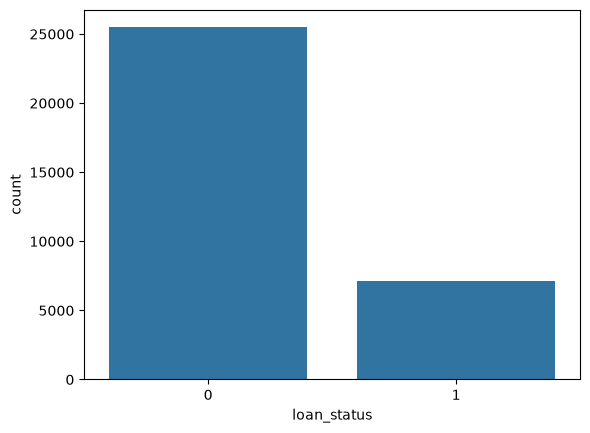

In [316]:
sns.countplot(x='loan_status', data=df)

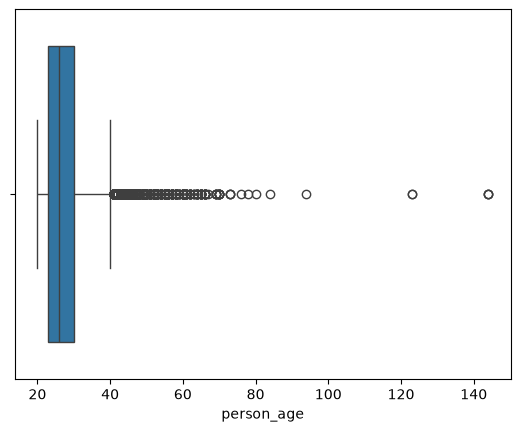

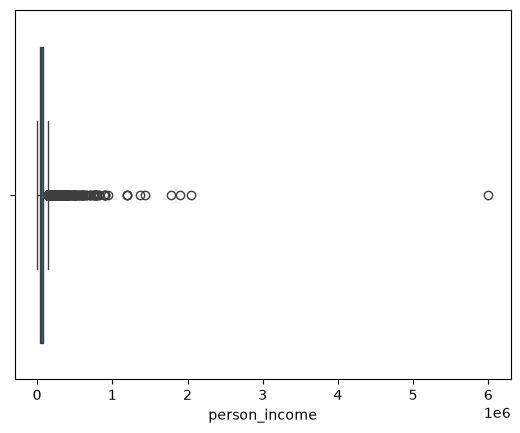

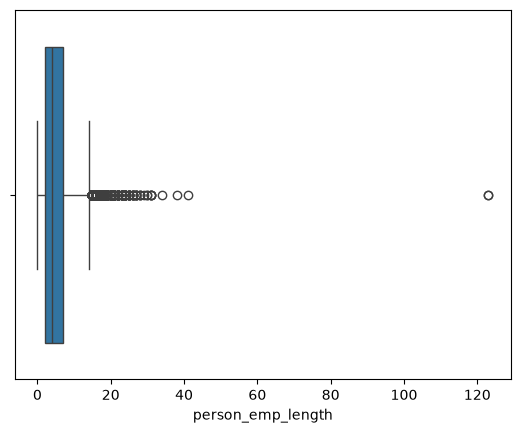

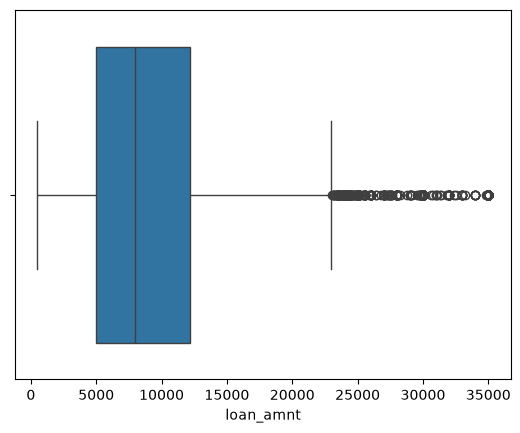

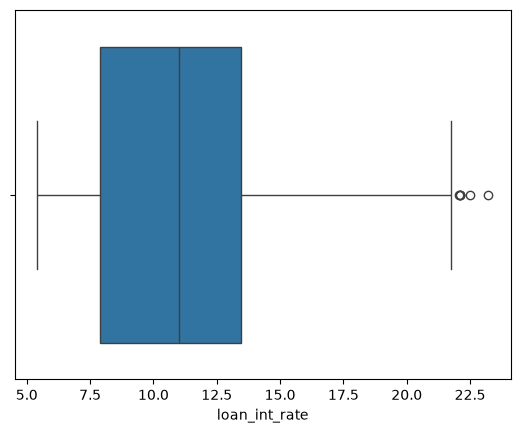

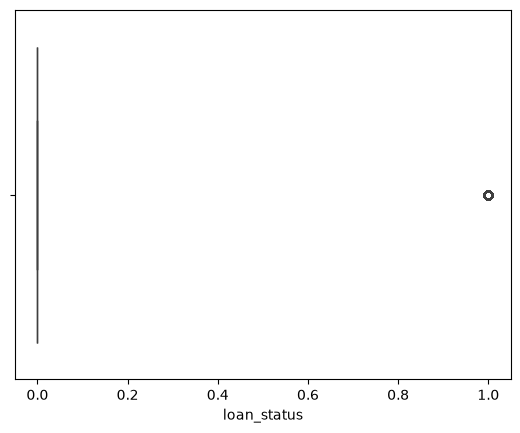

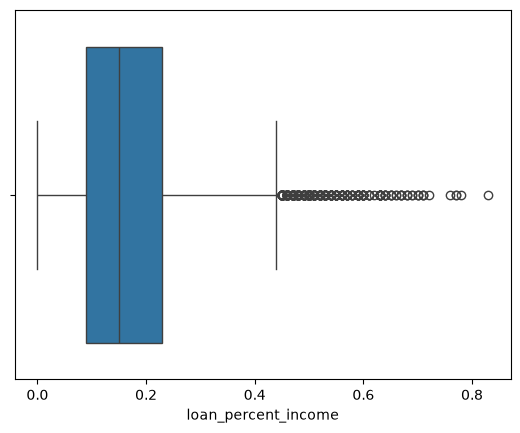

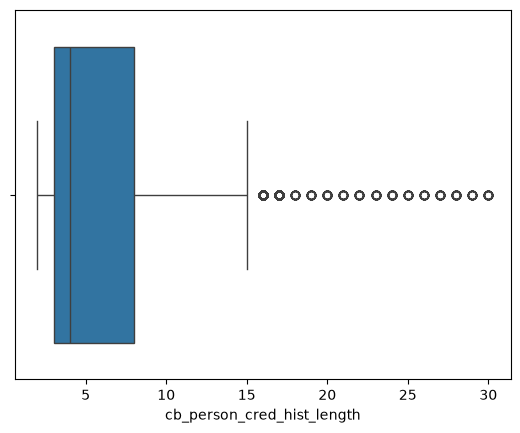

In [317]:
numerical_cols = df.select_dtypes(include=np.number).columns
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()



In [318]:
(df['person_age'] > 100).sum()

np.int64(5)

In [319]:
(df['person_emp_length'] > 60).sum() #person employ length tells us since how many years an employ has been working from

np.int64(2)

<Axes: >

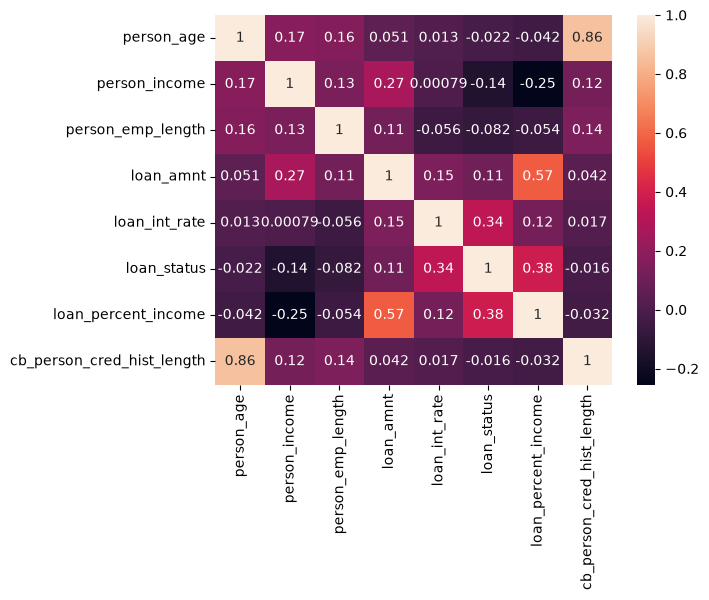

In [320]:
# correlation check - see how strongly features are strongly correlated to each other 
# we will use sns for this 
sns.heatmap(df.corr(numeric_only=True), annot = True)

In [321]:
# DATA VALIDATION AND OUTLIER HANDLING

df_copy = df.copy()

print(f"Original Rows: {df_copy.shape[0]}")

# Remove duplicate rows
df_copy.drop_duplicates(inplace=True)

print(f"Rows after dropping duplicates: {df_copy.shape[0]}")

# Remove impossible ages
# Keep people between 18 and 100 years old
df_copy = df_copy[
    (df_copy['person_age'] >= 18) &
    (df_copy['person_age'] <= 100)
]

# Remove invalid employment lengths
# Employment length cannot be greater than the person's age
# Also remove extreme employment lengths above 60 years
df_copy = df_copy[
    (df_copy['person_emp_length'] <= df_copy['person_age']) &
    (df_copy['person_emp_length'] <= 60)
]

print(f"Rows after validation: {df_copy.shape[0]}")

df_copy = df_copy[df_copy['loan_amnt'] > 0]

#check if the interest interest rate looks realistic
print("Loan interest rate range from (min:5.22 and max: 23.22)")
df_copy.head()

Original Rows: 32581
Rows after dropping duplicates: 32416
Rows after validation: 31522
Loan interest rate range from (min:5.22 and max: 23.22)


C:\Users\anshu\AppData\Local\Temp\ipykernel_25240\457482764.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_copy.drop_duplicates(inplace=True)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2


In [322]:
# Features, Target and Train-Test Split

X = df_copy.drop("loan_status", axis=1)
y = df_copy['loan_status']

In [323]:
# Train_Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

In [324]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income',
                'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
                    'cb_person_default_on_file']

In [325]:
# Class - Weights
# Logistic Regression has inbuilt class weights
# 0 -> no loan(most)
# 1 -> 1 yes loan
neg, pos = np.bincount(y_train)
scale_weights = neg/pos

In [326]:
# Data Preprocessing

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder




In [327]:
# Preprocessing for Logistic Regression : inpute + SCALE Numeric, input + One-Hot-Encoding
from sklearn.pipeline import Pipeline

preprocessor_lr = ColumnTransformer(
    transformers=[
        # Pipeline for numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        # Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [328]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
def evaluate_model(model_name, model, X_test, y_test, threshold=None):

    if threshold:
        y_pred = (y_pred_proba > threshold).astype(int)
    else:
        y_pred = model.predict(X)

    # Predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    print(f"Best Threshold: {best_threshold:.2f}")
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1: {f1:.2f}")

    # Classification Report
    class_report = classification_report(y_test, y_pred)
    print(class_report)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Label")
    plt.xlabel("Predicted Label")
    plt.show()

    # Precision-Recall Curve
    precision, recalls, threshold = precision_recall_curve(
        y_test,
        y_pred_proba
    )

    plt.plot(recalls, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

In [329]:
# Stratified Cross - Validation 
# - one single train-test split may not be reliabe 
# - we split th the training data into five folds instead 
# - each fold keeps the same default vs rapid ratio 
# - we check the model's score across all folds 
preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline for numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
           
        ]), numeric_cols),

        #Pipeline for ategorical columns 
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

In [330]:
# Logsictic Regression 

from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight = 'balanced', random_state=42))
])

In [331]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator = 300, max_depth = 5, learning_rate = 0.1, scale_pos_weight = scale_weights, n_jobs=-1
    ))
])


In [332]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}


In [333]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      print(f"Precision : {cv_results['test_precision'].mean()}")
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()
     

Logistic Regression
ROC-AUC : 0.8705112830525306
Accuracy : 0.8115949542892269
Precision : 0.5448226008889892
Recall : 0.7781450872359963
F1 : 0.6408013995933108

XGBoost
ROC-AUC : 0.9393848243386111
Accuracy : 0.9086724038455642
Precision : 0.7913354492271174
Recall : 0.7856749311294765
F1 : 0.7880291923045915



In [334]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nColumns expected by LR preprocessor:")
print(preprocessor_lr.transformers)

print("\nColumns expected by XGB preprocessor:")
print(preprocessor_xg.transformers)

X_train columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Columns expected by LR preprocessor:
[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']), ('cat', Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Missing', strategy='constant')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file'])]

Columns expected by XGB preprocessor:
[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))]), ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loa

In [335]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [336]:
# 

In [337]:
xg_model = Pipeline([
('preprocessor', preprocessor_xg),
('classifier', XGBClassifier(learning_rate=0.1,
    scale_pos_weights=scale_weights, random_state=42))
])
xg_model.fit(X_train, y_train)

c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:50:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weights" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

Best Threshold: 0.71
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1: 0.65
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



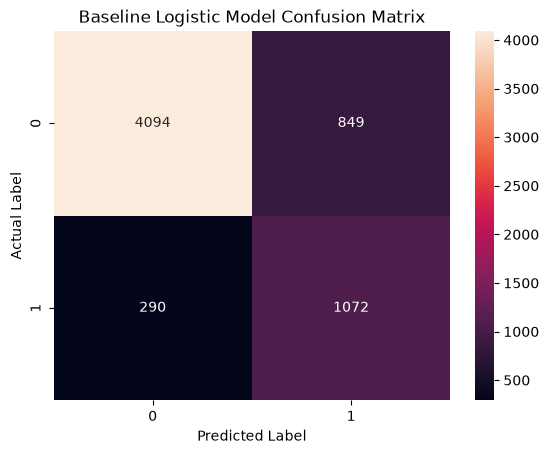

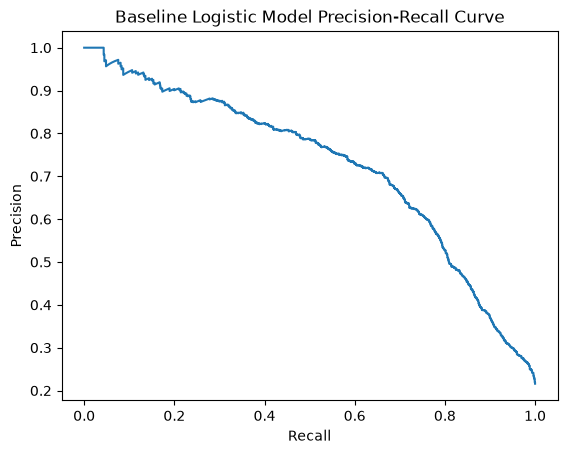

In [338]:
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

Best Threshold: 0.71
Accuracy: 0.94
Precision: 0.97
Recall: 0.73
F1: 0.83
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



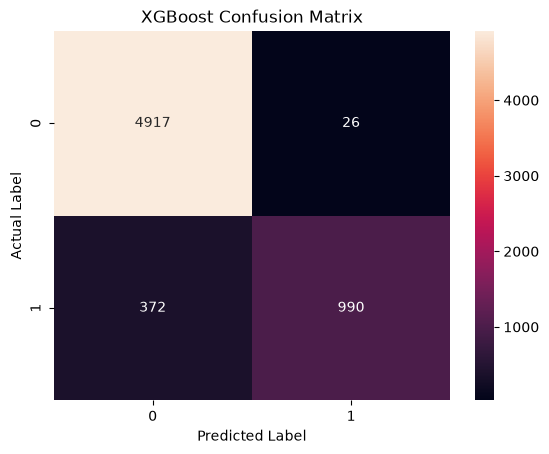

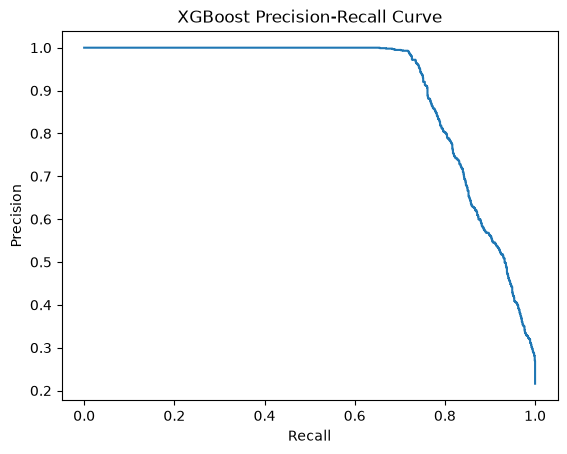

In [339]:
evaluate_model("XGBoost", xg_model, X_test, y_test)

In [340]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),  # Number of trees
    "classifier__max_depth": randint(3, 9),         # Maximum depth of each tree
    "classifier__learning_rate": uniform(0.01, 0.5), # Contribution of each tree
    "classifier__subsample": uniform(0.4, 0.6),      # Fraction of rows used
    "classifier__colsample_bytree": uniform(0.4, 0.6), # Fraction of columns used
    "classifier__min_child_weight": randint(1, 10),  # Minimum weight needed for a split
    "classifier__gamma": uniform(0, 5)               # Minimum improvement required for a split
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gammaa -> less splits -> simpler tree -> low overfitting risk 

In [341]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)
     

Fitting 5 folds for each of 150 candidates, totalling 750 fits


c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:58:28] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weights" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....00181837365B0>, 'classifier__gamma': <scipy.stats....00181FCDDB1D0>, 'classifier__learning_rate': <scipy.stats....001818C008E50>, 'classifier__max_depth': <scipy.stats....0018186F65220>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

Best Threshold: 0.71
Accuracy: 0.94
Precision: 0.96
Recall: 0.74
F1: 0.84
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.74      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.87      0.90      6305
weighted avg       0.94      0.94      0.94      6305



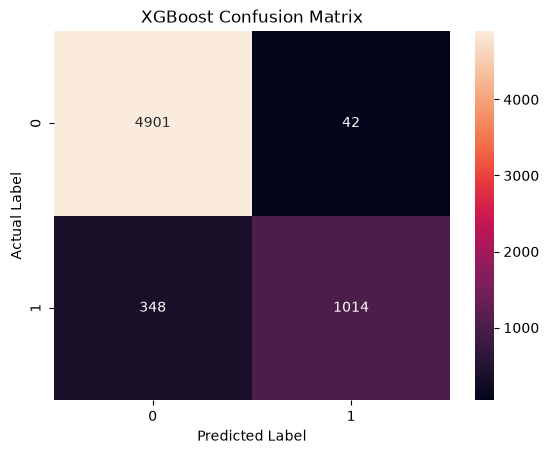

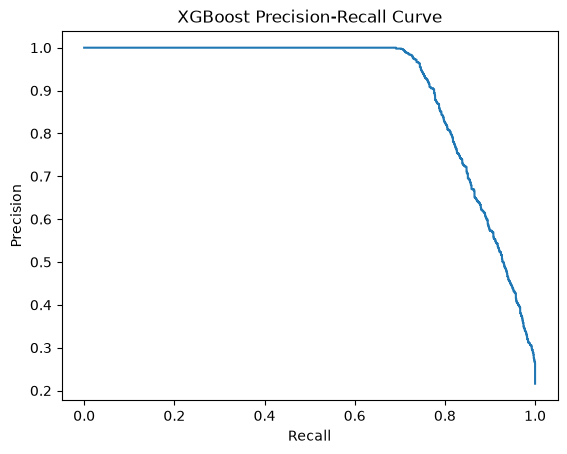

In [342]:
# passing the XGBoost model after performing hyperparameter tuning 
evaluate_model("XGBoost", random_search, X_test, y_test)

In [343]:
# Optimizing the Classification Threshold 
from sklearn.metrics import precision_recall_curve
import numpy as np

# 1. Get the probability of class 1 (default) for every test sample
prob = xg_model.predict_proba(X_test)[:, 1]

# 2. Calculate precision and recall at different probability thresholds
precision, recall, thresholds = precision_recall_curve(y_test, prob)

# 3. Calculate F1-score for every threshold
f1 = 2 * (precision * recall) / (precision + recall + 1e-9)

# 4. Find the threshold that gives the highest F1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

print("Best threshold:", best_threshold)
print("Best F1-score:", f1[best])

# 5. Convert probabilities into 0/1 predictions using the best threshold
y_pred = (prob >= best_threshold).astype(int)

# 6. Evaluate the predictions
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Best threshold: 0.46085197
Best F1-score: 0.8369565212487625
Accuracy: 0.9381443298969072
Precision: 0.9718446601941747
Recall: 0.7349486049926579
F1: 0.8369565217391305


In [344]:
# SHAP helps us understand why thee model makes a decision
# It is a way of explaining a 'black box ' modell
# SHAP tells you how each feature contributed
# SHAP tells which features pushed the predictions up or down and hwo much ?

# local explanation -> answers why did the model make this prediction for thsi student, why one specific applicant got their score and breaks down feature by feature 
# gloabal explanation -> shows if a featres matter most overall also shows if a feature increases or decreases a risk. Which feature are generally most important to the model.
import shap
# 2. get the xgboost classifier model out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']
# 3. transfor x test using the same preprocessing used for training 
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)
# 4 get feature names afer one hot encoding, so plots are trainable 
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()
#5. convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)
#6. Create to a dataframe for cleaner SHAP plots
explainer = shap.TreeExplainer(xgb_classifier)
#7. calculate SHAP values for every row in the test set 
shap_values = explainer.shap_values(X_test_df)


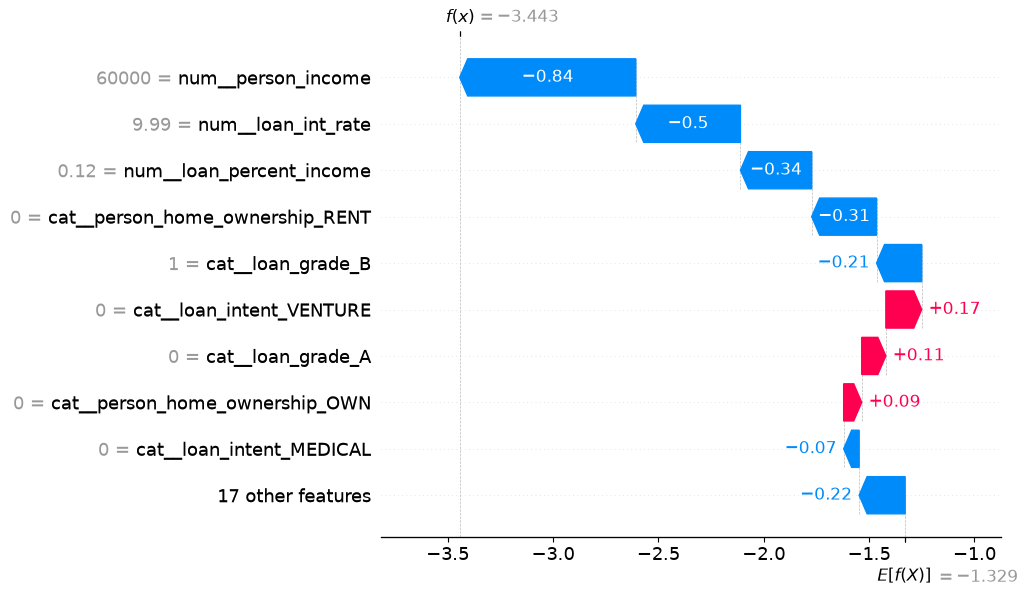

In [345]:
# LOCAL EXPLANATION 
#1 Pick one row to explain, e.g the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot to show how each feature pushed the prediction up or down 
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

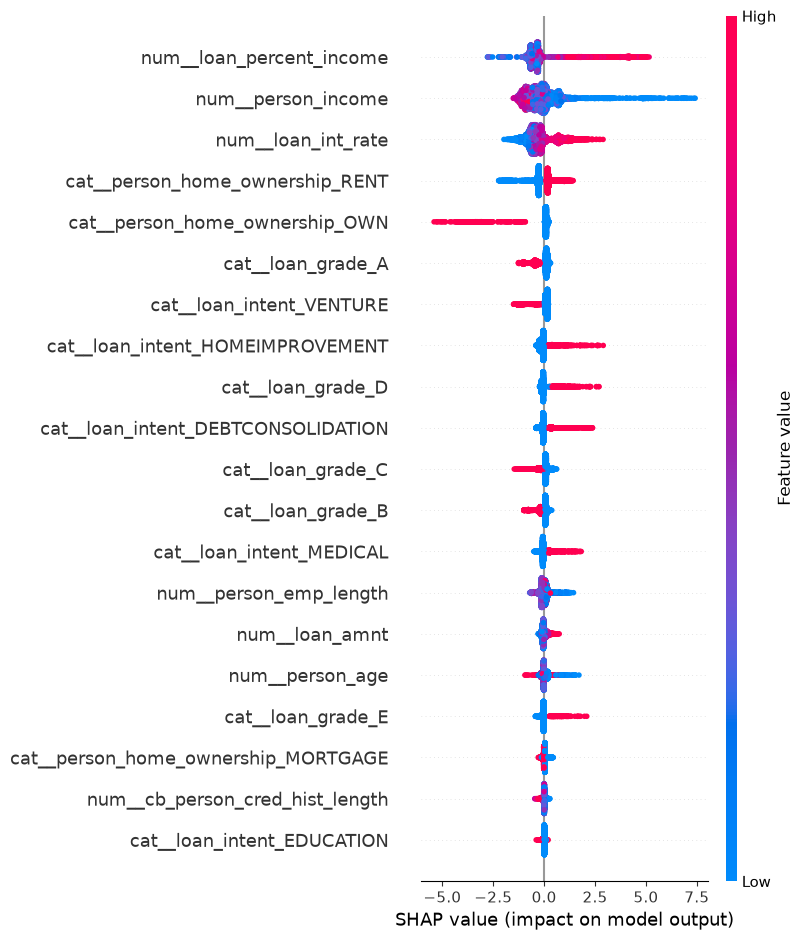

In [346]:
# GLOBAL EXPLANATION 
shap.summary_plot(shap_values, X_test_df)

In [347]:
# Probability Calibiration
# Probability calibration makes a model’s predicted probabilities match the actual likelihood of an outcome. 🎯

#Example: among customers predicted with 70% probability of default, roughly 70% should actually default."""Mehods by which we can fix the poorly calliberated model
"""1. Plat caling / Sigmoid -> Adjust the probabilities using a sigmoid curve
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear caliberation)
3. Temperature Scaling -> Adjust the confidenece of neural-network prediction using one temperature"""


'1. Plat caling / Sigmoid -> Adjust the probabilities using a sigmoid curve\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear caliberation)\n3. Temperature Scaling -> Adjust the confidenece of neural-network prediction using one temperature'

c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:58:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weights" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:58:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weights" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:58:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weights" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\anshu\Desktop\Credit Default Risk Prediction\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:58:5

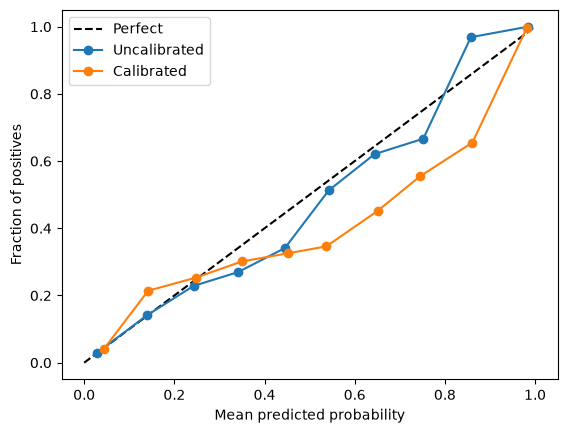

In [348]:
# Caliberated XGBoost Model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method='sigmoid',
    cv=5
)

calibrated_model.fit(X_train, y_train)

# Get probabilities
uncalibrated = best_model.predict_proba(X_test)[:, 1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

# Create calibration curves
actual_uncal, predicted_uncal = calibration_curve(
    y_test, uncalibrated, n_bins=10
)

actual_cal, predicted_cal = calibration_curve(
    y_test, calibrated, n_bins=10
)

# Plot
plt.plot([0, 1], [0, 1], 'k--', label="Perfect")

plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label="Calibrated"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.legend()
plt.show()

In [349]:
# Analyzing False Positive and False Negative 

#The model will not be perfect.
#False positives are safe people wrongly marked risky.
#False negatives are risky people wrongly marked safe.
#We study these cases to understand where the model struggles.

# Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)
# Create a dataframe to easily compare the actual and predicted sataframes 
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred



In [350]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,0
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,0
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [351]:
#FALSE POSITIVE = MODEL PREDICTED 1 BUT THE ACTUAL VALUE WAS 0 
false_positive = result_df[(result_df['actual']) == 0 & (result_df['predicted'] == 1)]
#FALSE NEGATIVE = MODEL PREDICTED 0 BUT THE ACTUAL WAS 1
false_negative = result_df[(result_df['actual']) == 1 & (result_df['predicted'] == 0)]


In [352]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")
#False Negative < False Positive

False Positive : 4943
False Negative : 390


In [353]:
import joblib 

joblib.dump(calibrated_model, 'credit_risk_model.pkl')
joblib.dump(best_threshold, 'best_threshold.pkl')

['best_threshold.pkl']

In [354]:
from sklearn.metrics import precision_recall_curve
import numpy as np 

#1. Get probabilities from the CALIBRATED model, not the old xg_model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

#2. Re-run the same threshold search, now on the correct probabilities scale
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2* (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print(f"New threshold: {best_threshold}")

New threshold: 0.5888876140081976


In [355]:
joblib.dump(best_threshold, 'best_threshold.pkl')

['best_threshold.pkl']